LAB 10: CSP - MAP COLOURING OF AUSTRALIA
Backtracking + MRV + Forward Checking
+ WA = Red
  + NT = Green
    + SA = Blue
      + Q = Red
        + NSW = Green
          + V = Red
            + T = Red

------------------------------------------------------------
SOLUTION FOUND

WA    -> Red
NT    -> Green
SA    -> Blue
Q     -> Red
NSW   -> Green
V     -> Red
T     -> Red

All constraints satisfied: True
Assignments tried: 7
Backtracks: 0


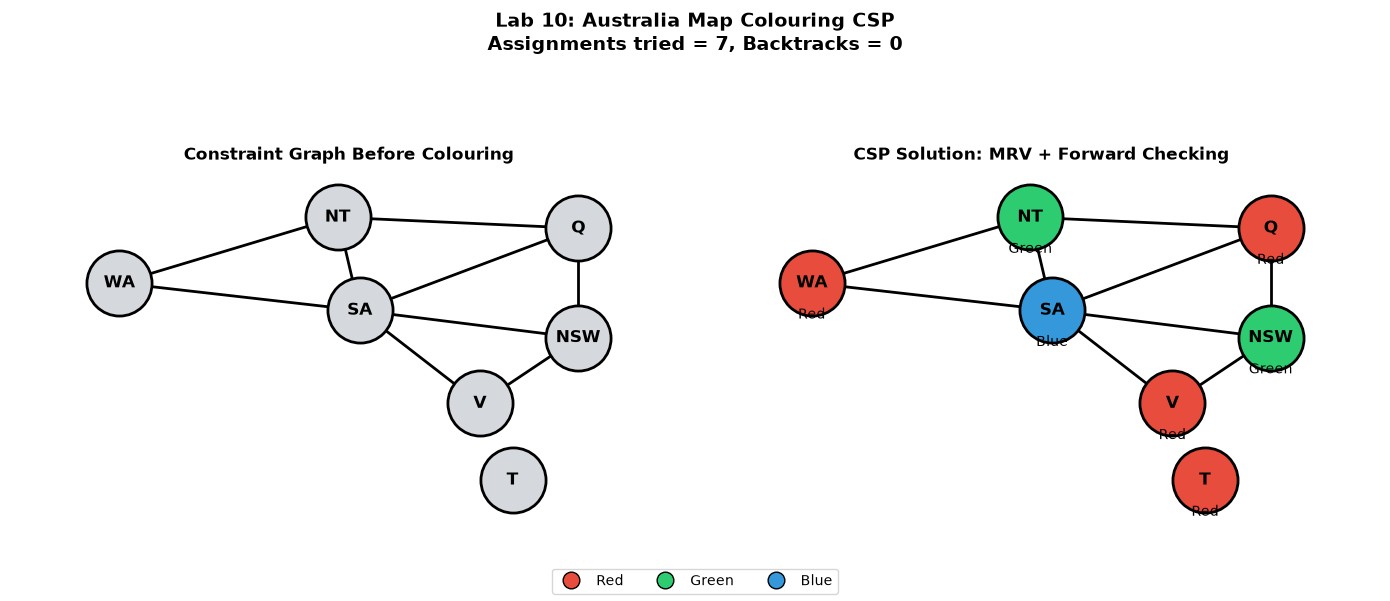

Figure saved as lab10_output.png


In [2]:
import matplotlib.pyplot as plt

VARIABLES = ["WA", "NT", "SA", "Q", "NSW", "V", "T"]
COLORS = ["Red", "Green", "Blue"]
DOMAINS = {v: COLORS.copy() for v in VARIABLES}

NEIGHBORS = {
    "WA": ["NT", "SA"],
    "NT": ["WA", "SA", "Q"],
    "SA": ["WA", "NT", "Q", "NSW", "V"],
    "Q": ["NT", "SA", "NSW"],
    "NSW": ["Q", "SA", "V"],
    "V": ["SA", "NSW"],
    "T": []
}

POS = {
    "WA": (0, 2.2),
    "NT": (2, 3.4),
    "SA": (2.2, 1.7),
    "Q": (4.2, 3.2),
    "NSW": (4.2, 1.2),
    "V": (3.3, 0),
    "T": (3.6, -1.4)
}

COLOR_CODES = {
    "Red": "#e74c3c",
    "Green": "#2ecc71",
    "Blue": "#3498db"
}

class CSP:
    def __init__(self, variables, domains, neighbors):
        self.variables = variables
        self.domains = domains
        self.neighbors = neighbors
        self.assign_count = 0
        self.backtrack_count = 0

    def is_consistent(self, var, color, assignment):
        return all(
            assignment.get(n) != color
            for n in self.neighbors[var]
        )

    def select_variable_mrv(self, assignment, domains):
        unassigned = [
            v for v in self.variables
            if v not in assignment
        ]
        return min(unassigned, key=lambda v: len(domains[v]))

    def backtrack(self, assignment, domains, depth=0):
        if len(assignment) == len(self.variables):
            return assignment.copy()

        var = self.select_variable_mrv(assignment, domains)
        indent = "  " * depth

        for color in domains[var]:
            self.assign_count += 1

            if not self.is_consistent(var, color, assignment):
                print(f"{indent}X {var} = {color}: conflict")
                continue

            assignment[var] = color
            print(f"{indent}+ {var} = {color}")

            new_domains = {
                v: d.copy() for v, d in domains.items()
            }

            dead_end = False

            for neighbor in self.neighbors[var]:
                if neighbor not in assignment:
                    if color in new_domains[neighbor]:
                        new_domains[neighbor].remove(color)

                    if not new_domains[neighbor]:
                        dead_end = True
                        break

            if not dead_end:
                result = self.backtrack(
                    assignment, new_domains, depth + 1
                )

                if result is not None:
                    return result

            del assignment[var]
            self.backtrack_count += 1
            print(f"{indent}<- Backtrack: undo {var} = {color}")

        return None

    def solve(self):
        domains = {
            v: d.copy() for v, d in self.domains.items()
        }
        return self.backtrack({}, domains)

def draw_graph(ax, assignment, title):
    drawn_edges = set()

    for region, neighbors in NEIGHBORS.items():
        for neighbor in neighbors:
            edge = tuple(sorted((region, neighbor)))

            if edge not in drawn_edges:
                x1, y1 = POS[region]
                x2, y2 = POS[neighbor]

                ax.plot(
                    [x1, x2], [y1, y2],
                    color="black", linewidth=2, zorder=1
                )
                drawn_edges.add(edge)

    for region, (x, y) in POS.items():
        color = COLOR_CODES.get(
            assignment.get(region), "#d5d8dc"
        )

        ax.scatter(
            x, y, s=2200, color=color,
            edgecolors="black", linewidths=2, zorder=2
        )

        ax.text(
            x, y, region,
            ha="center", va="center",
            fontsize=12, fontweight="bold", zorder=3
        )

        if region in assignment:
            ax.text(
                x, y - 0.65, assignment[region],
                ha="center", fontsize=10
            )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlim(-1, 5.2)
    ax.set_ylim(-2.4, 4.3)
    ax.axis("off")

def show_result(solution, csp):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    draw_graph(axes[0], {}, "Constraint Graph Before Colouring")
    draw_graph(axes[1], solution, "CSP Solution: MRV + Forward Checking")

    handles = [
        plt.Line2D(
            [0], [0], marker="o", color="w",
            markerfacecolor=COLOR_CODES[c],
            markeredgecolor="black",
            markersize=12, label=c
        )
        for c in COLORS
    ]

    fig.legend(handles=handles, loc="lower center", ncol=3)

    fig.suptitle(
        "Lab 10: Australia Map Colouring CSP\n"
        f"Assignments tried = {csp.assign_count}, "
        f"Backtracks = {csp.backtrack_count}",
        fontsize=14, fontweight="bold"
    )

    fig.tight_layout(rect=[0, 0.08, 1, 0.88])
    fig.savefig("lab10_output.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Figure saved as lab10_output.png")

print("=" * 60)
print("LAB 10: CSP - MAP COLOURING OF AUSTRALIA")
print("Backtracking + MRV + Forward Checking")
print("=" * 60)

csp = CSP(VARIABLES, DOMAINS, NEIGHBORS)
solution = csp.solve()

print("\n" + "-" * 60)

if solution is not None:
    print("SOLUTION FOUND\n")

    for region in VARIABLES:
        print(f"{region:5} -> {solution[region]}")

    valid = all(
        solution[a] != solution[b]
        for a in VARIABLES
        for b in NEIGHBORS[a]
    )

    print(f"\nAll constraints satisfied: {valid}")
    print(f"Assignments tried: {csp.assign_count}")
    print(f"Backtracks: {csp.backtrack_count}")

    show_result(solution, csp)
else:
    print("No solution exists.")
